# Selective Intent Routing with Abstention

**Question.** How often does a score-based fallback catch unsupported requests when the router aims to accept at least 95% of supported validation requests?

We train one classifier and compare three routing policies. Run the notebook in order from the project directory. The setup cell uses the official [CLINC150 dataset](https://github.com/clinc/oos-eval) and downloads it on the first run if needed.

In [ ]:
import json
import math
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.pipeline import make_pipeline

DATA_URL = "https://raw.githubusercontent.com/clinc/oos-eval/master/data/data_full.json"
DATA_PATH = Path("data_full.json")
OUTPUT_DIR = Path("results")
TARGET_ACCEPTANCE = 0.95
OUT_OF_SCOPE = "oos"

if DATA_PATH.exists():
    dataset = json.loads(DATA_PATH.read_text(encoding="utf-8-sig"))
else:
    with urlopen(DATA_URL, timeout=30) as response:
        data_bytes = response.read()
    dataset = json.loads(data_bytes)
    DATA_PATH.write_bytes(data_bytes)

split_sizes = {
    "train": 15_000,
    "val": 3_000,
    "oos_val": 100,
    "test": 4_500,
    "oos_test": 1_000,
}
for split, expected_size in split_sizes.items():
    if len(dataset.get(split, [])) != expected_size:
        raise ValueError(f"Expected {expected_size:,} examples in {split}. Use CLINC150 data_full.json.")

print(f"scikit-learn {sklearn.__version__}")
display(pd.Series(split_sizes, name="Examples").to_frame())

scikit-learn 1.6.1


,Examples
train,15000
val,3000
oos_val,100
test,4500
oos_test,1000


## 1. Train the intent classifier

TF-IDF turns word unigrams and bigrams into numerical features. Logistic regression learns which features predict each supported intent. Fitting the pipeline on the training split also keeps the vocabulary and document frequencies independent of validation and test.

In [ ]:
train_messages, train_labels = zip(*dataset["train"])
model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(C=4.0, solver="lbfgs", max_iter=500),
)
model.fit(train_messages, train_labels)

print(f"Trained on {len(train_messages):,} requests across {len(model.classes_)} intents.")
print(f"Vocabulary size: {len(model[0].vocabulary_):,}")

Trained on 15,000 requests across 150 intents.
Vocabulary size: 11,860


## 2. Score validation requests

The top score is the highest probability assigned to any supported intent. The score gap is the distance between the top two probabilities. Both scores come from the same classifier, so comparing policies isolates the effect of the rejection rule.

In [ ]:
def score_requests(examples):
    messages, labels = zip(*examples)
    probabilities = model.predict_proba(messages)
    top_indices = probabilities.argmax(axis=1)
    top_scores = probabilities[np.arange(len(messages)), top_indices]
    runner_up_scores = np.partition(probabilities, -2, axis=1)[:, -2]
    return pd.DataFrame({
        "message": messages,
        "true_intent": labels,
        "predicted_intent": model.classes_[top_indices],
        "top_score": top_scores,
        "score_gap": top_scores - runner_up_scores,
    })


validation = score_requests(dataset["val"] + dataset["oos_val"])
supported_validation = validation[validation["true_intent"] != OUT_OF_SCOPE]
validation_accuracy = (
    supported_validation["predicted_intent"] == supported_validation["true_intent"]
).mean()
print(f"Always-route validation accuracy on supported requests: {validation_accuracy:.2%}")
display(validation.groupby(validation["true_intent"].eq(OUT_OF_SCOPE)).head(3))

Always-route validation accuracy on supported requests: 90.07%


,message,true_intent,predicted_intent,top_score,score_gap
0,"in spanish, meet me tomorrow is said how",translate,translate,0.210191,0.129547
1,"in french, how do i say, see you later",translate,translate,0.752334,0.630154
2,how do you say hello in japanese,translate,translate,0.891218,0.878041
3000,set a warning for when my bank account starts ...,oos,account_blocked,0.337462,0.087875
3001,a show on broadway,oos,transactions,0.361288,0.338865
3002,who has the best record in the nfl,oos,food_last,0.090422,0.023741


## 3. Choose thresholds on validation

Sort the supported validation scores from lowest to highest. The lowest score among the top 95% is the highest possible cutoff that still accepts at least 95%. With a `>=` rule, tied scores at the cutoff can bring actual acceptance slightly above the target.

In [ ]:
policy_scores = {"Top score": "top_score", "Score gap": "score_gap"}
thresholds = {}
validation_rows = []
required_acceptances = math.ceil(TARGET_ACCEPTANCE * len(supported_validation))
unsupported_validation = validation[validation["true_intent"] == OUT_OF_SCOPE]

for policy, score_column in policy_scores.items():
    sorted_scores = np.sort(supported_validation[score_column].to_numpy())
    threshold = float(sorted_scores[-required_acceptances])
    thresholds[policy] = threshold
    validation_rows.append({
        "policy": policy,
        "threshold": threshold,
        "supported_acceptance": (supported_validation[score_column] >= threshold).mean(),
        "unsupported_rejection": (unsupported_validation[score_column] < threshold).mean(),
    })

validation_summary = pd.DataFrame(validation_rows).set_index("policy")
display(validation_summary.assign(
    threshold=validation_summary["threshold"].map("{:.6f}".format),
    supported_acceptance=validation_summary["supported_acceptance"].map("{:.2%}".format),
    unsupported_rejection=validation_summary["unsupported_rejection"].map("{:.2%}".format),
))

,threshold,supported_acceptance,unsupported_rejection
policy,,,
Top score,0.112562,95.00%,60.00%
Score gap,0.027281,95.00%,43.00%


## 4. Compare routing policies on the held-out test set

The cutoff for each policy comes from the validation cell above. Report the actual test acceptance alongside the unsupported routing rate and accuracy among accepted supported requests.

In [ ]:
test = score_requests(dataset["test"] + dataset["oos_test"])
supported = test["true_intent"].ne(OUT_OF_SCOPE)
correct = test["predicted_intent"].eq(test["true_intent"])
supported_total = int(supported.sum())
unsupported_total = int((~supported).sum())

test_decisions = {"Always route": pd.Series(True, index=test.index)}
for policy, score_column in policy_scores.items():
    test_decisions[policy] = test[score_column] >= thresholds[policy]

results = []
for policy, accepted in test_decisions.items():
    supported_accepted = int((supported & accepted).sum())
    unsupported_routed = int((~supported & accepted).sum())
    correct_accepted = int((supported & accepted & correct).sum())
    results.append({
        "policy": policy,
        "threshold": thresholds.get(policy),
        "supported_accepted": supported_accepted,
        "supported_total": supported_total,
        "unsupported_routed": unsupported_routed,
        "unsupported_total": unsupported_total,
        "correct_accepted_supported": correct_accepted,
        "supported_acceptance": supported_accepted / supported_total,
        "unsupported_routing": unsupported_routed / unsupported_total,
        "unsupported_rejection": (unsupported_total - unsupported_routed) / unsupported_total,
        "accuracy_among_accepted_supported": (
            correct_accepted / supported_accepted if supported_accepted else np.nan
        ),
    })

summary = pd.DataFrame(results).set_index("policy")
rate_columns = [
    "supported_acceptance",
    "unsupported_routing",
    "unsupported_rejection",
    "accuracy_among_accepted_supported",
]
display(summary[rate_columns].map("{:.2%}".format))
OUTPUT_DIR.mkdir(exist_ok=True)
summary.to_csv(OUTPUT_DIR / "test_metrics.csv")

,supported_acceptance,unsupported_routing,unsupported_rejection,accuracy_among_accepted_supported
policy,,,,
Always route,100.00%,100.00%,0.00%,90.60%
Top score,95.31%,42.60%,57.40%,93.10%
Score gap,95.69%,56.40%,43.60%,93.13%


## 5. Plot the validation trade-off

Treat a supported request as the positive class and sweep the acceptance threshold. The true-positive rate is supported acceptance. One minus the false-positive rate is unsupported rejection. Each marker shows the validation operating point selected for a policy.

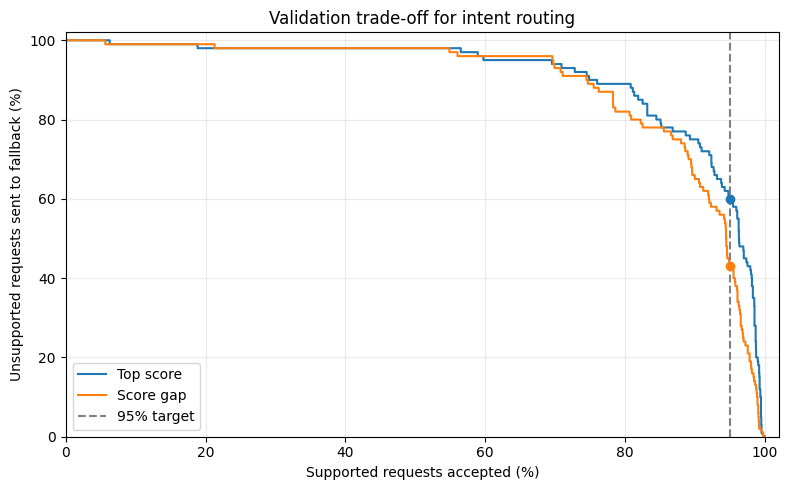

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
is_supported = validation["true_intent"].ne(OUT_OF_SCOPE)
for policy, score_column in policy_scores.items():
    unsupported_routed, supported_accepted, _ = roc_curve(
        is_supported, validation[score_column], drop_intermediate=False
    )
    line, = ax.plot(
        100 * supported_accepted, 100 * (1 - unsupported_routed), label=policy
    )
    point = validation_summary.loc[policy]
    ax.scatter(
        100 * point["supported_acceptance"],
        100 * point["unsupported_rejection"],
        color=line.get_color(),
        zorder=3,
    )

ax.axvline(
    100 * TARGET_ACCEPTANCE, color="0.5", linestyle="--", label=f"{TARGET_ACCEPTANCE:.0%} target"
)
ax.set(
    title="Validation trade-off for intent routing",
    xlabel="Supported requests accepted (%)",
    ylabel="Unsupported requests sent to fallback (%)",
    xlim=(0, 102),
    ylim=(0, 102),
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_tradeoff.png", dpi=200)
plt.show()

## 6. Inspect actual test errors

For each threshold policy, identify unsupported requests that were routed, supported requests that went to fallback, and supported requests that reached the wrong intent. The exported CSV includes the routing decisions and error categories for every test message.

In [ ]:
for policy, score_column in policy_scores.items():
    accepted = test_decisions[policy]
    slug = score_column
    test[f"{slug}_accepted"] = accepted
    test[f"{slug}_error"] = np.select(
        [~supported & accepted, supported & ~accepted, supported & accepted & ~correct],
        ["unsupported routed", "supported rejected", "wrong supported intent"],
        default="",
    )
    errors = test.loc[test[f"{slug}_error"].ne("")]
    print(f"{policy} — error counts")
    display(errors[f"{slug}_error"].value_counts())
    print(f"{policy} — one example per error type")
    display(
        errors.groupby(f"{slug}_error").head(1)[
            ["message", "true_intent", "predicted_intent", score_column, f"{slug}_error"]
        ]
    )

test.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

Top score — error counts


,count
top_score_error,
unsupported routed,426
wrong supported intent,296
supported rejected,211


Top score — one example per error type


,message,true_intent,predicted_intent,top_score,top_score_error
1,what's the spanish word for pasta,translate,translate,0.095517,supported rejected
4,what's the word for trees in norway,translate,definition,0.188849,wrong supported intent
4508,at what age can someone get a card,oos,how_old_are_you,0.115232,unsupported routed


Score gap — error counts


,count
score_gap_error,
unsupported routed,564
wrong supported intent,296
supported rejected,194


Score gap — one example per error type


,message,true_intent,predicted_intent,score_gap,score_gap_error
4,what's the word for trees in norway,translate,definition,0.038441,wrong supported intent
8,what's the french word you use for potato,translate,definition,0.001776,supported rejected
4500,how much has the dow changed today,oos,income,0.031561,unsupported routed


In [ ]:
import pandas as pd

# Load and display the final metrics
test_metrics = pd.read_csv('results/test_metrics.csv')
display(test_metrics)

,policy,threshold,supported_accepted,supported_total,unsupported_routed,unsupported_total,correct_accepted_supported,supported_acceptance,unsupported_routing,unsupported_rejection,accuracy_among_accepted_supported
0,Always route,NaN,4500,4500,1000,1000,4077,1.000000,1.000,0.000,0.906000
1,Top score,0.112562,4289,4500,426,1000,3993,0.953111,0.426,0.574,0.930986
2,Score gap,0.027281,4306,4500,564,1000,4010,0.956889,0.564,0.436,0.931259


In [ ]:
import shutil
from google.colab import files

# Create a zip archive of the results directory
shutil.make_archive('results', 'zip', 'results')

# Trigger the browser download prompt
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Report notes

Use the metrics table to report the unsupported requests caught at the observed supported acceptance. Inspect the examples to explain how overlapping vocabulary or ambiguous phrasing may have affected the decision. Compare policies at similar acceptance levels, since accepting fewer supported requests may make a policy look better at rejection.

Dataset reference: [Larson et al., EMNLP-IJCNLP 2019](https://aclanthology.org/D19-1131/).